<a href="https://colab.research.google.com/github/akatsushikami-arch/HW/blob/main/t_SHE_2%2C_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PCA (Principal Component Analysis)

$
X =
\begin{bmatrix}
x_{1}^{(1)} & x_{2}^{(1)} & \dots & x_{n}^{(1)} \\
x_{1}^{(2)} & x_{2}^{(2)} & \dots & x_{n}^{(2)} \\
\vdots & \vdots &  & \vdots \\
x_{1}^{(m)} & x_{2}^{(m)} & \dots & x_{n}^{(m)} \\
\end{bmatrix},
\:
\tilde {X} =
\begin{bmatrix}
x_{1}^{(1)} - \bar x_{1} & x_{2}^{(1)} - \bar x_{2} & \dots
& x_{n}^{(1)} - \bar x_{n} \\
x_{1}^{(2)} - \bar x_{1} & x_{2}^{(2)} - \bar x_{2} & \dots
& x_{n}^{(2)} - \bar x_{n} \\
\vdots & \vdots &  & \vdots \\
x_{1}^{(m)} - \bar x_{1} & x_{2}^{(m)} - \bar x_{2} & \dots
& x_{n}^{(m)} - \bar x_{n} \\
\end{bmatrix}
$


$
\tilde {X}^{\,T}\tilde X =
\begin{bmatrix}
\sum_1^m (x_1^{(k)} - \bar x_1)^2 & \sum_1^m (x_1^{(k)} - \bar x_1)
(x_2^{(k)} - \bar x_2) & \dots
& \sum_1^m (x_1^{(k)} - \bar x_1)(x_n^{(k)} - \bar x_{n}) \\
\sum_1^m (x_2^{(k)} - \bar x_2)(x_1^{(k)} - \bar x_1) & \sum_1^m (x_2^{(k)} - \bar x_2)^2 & \dots
& \sum_1^m (x_2^{(k)} - \bar x_2)(x_n^{(k)} - \bar x_{n}) \\
\vdots & \vdots & & \vdots \\
\sum_1^m (x_n^{(k)} - \bar x_n)(x_1^{(k)} - \bar x_1) &
\sum_1^m (x_n^{(k)} - \bar x_n)(x_2^{(k)} - \bar x_2) & \dots
& \sum_1^m (x_n^{(k)} - \bar x_n)^2
\end{bmatrix}
$

$
\Sigma = \frac{1}{m-1}\tilde X^{\,T}X,\:
\Sigma v = \lambda v
$

# Example with synthetic data

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
np.random.seed(42)
n_samples = 100
x_1 = np.random.normal(0, 1, n_samples)
#x_2 = 0.5 * x_1 + np.random.normal(0, 0.3, n_samples)
x_2 = np.random.normal(0, 0.3, n_samples)
X = np.column_stack([x_1, x_2])


In [ ]:
X_std = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
cov_matrix = X_std.T @ X_std / (n_samples - 1)
#cov_matrix = np.cov(X_std.T)

print('Ковариационная матрица')
print('-' * 25)
print(cov_matrix)


Ковариационная матрица
-------------------------
[[ 1.01010101 -0.13780021]
 [-0.13780021  1.01010101]]


In [ ]:
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)
idx = eigenvalues.argsort()[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]
print('Собственные значения')
print('-' * 23)
print(eigenvalues)
print('\nОбъясненная дисперсия')
print('-' * 23)
print(eigenvalues / eigenvalues.sum())


Собственные значения
-----------------------
[1.14790122 0.8723008 ]

Объясненная дисперсия
-----------------------
[0.56821111 0.43178889]


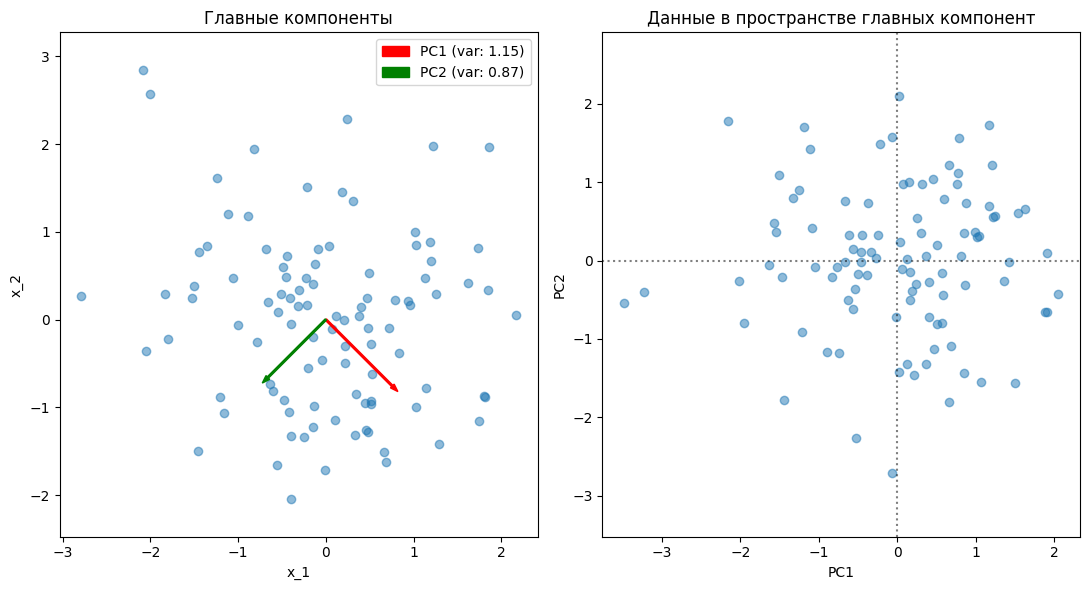

In [ ]:
plt.figure(figsize=(11, 6))

plt.subplot(1, 2, 1)
plt.scatter(X_std[:, 0], X_std[:, 1], alpha=0.5)
plt.arrow(0, 0,
          eigenvectors[0, 0] * np.sqrt(eigenvalues[0]),
          eigenvectors[1, 0] * np.sqrt(eigenvalues[0]),
          color='r',
          width=0.02,
          alpha=1,
          label=f'PC1 (var: {eigenvalues[0]:.2f})')
plt.arrow(0, 0,
          eigenvectors[0, 1] * np.sqrt(eigenvalues[1]),
          eigenvectors[1, 1] * np.sqrt(eigenvalues[1]),
          color='g',
          width=0.02,
          alpha=1,
          label=f'PC2 (var: {eigenvalues[1]:.2f})')
plt.legend()
plt.title('Главные компоненты')
plt.xlabel('x_1')
plt.ylabel('x_2')
plt.axis('equal')

plt.subplot(1, 2, 2)
X_transformed = X_std @ eigenvectors
plt.scatter(X_transformed[:, 0], X_transformed[:, 1], alpha=0.5)
plt.axhline(y=0, color='k', linestyle='dotted', alpha=0.5)
plt.axvline(x=0, color='k', linestyle='dotted', alpha=0.5)
plt.title('Данные в пространстве главных компонент')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.axis('equal')

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.decomposition import PCA

pca = PCA()
X_sklearn = pca.fit_transform(X_std)
print('Собственные значения')
print('-' * 23)
print(pca.explained_variance_)
print('\nОбъясненная дисперсия')
print('-' * 23)
print(pca.explained_variance_ratio_)


Собственные значения
-----------------------
[1.14790122 0.8723008 ]

Объясненная дисперсия
-----------------------
[0.56821111 0.43178889]


# Another example

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.decomposition import PCA


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


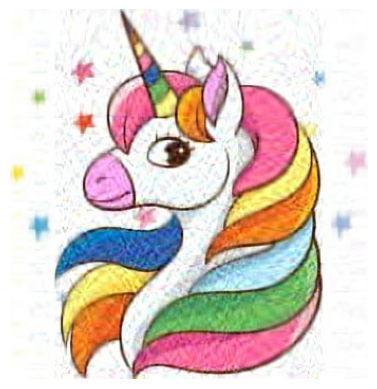

In [ ]:
image = Image.open('/content/drive/MyDrive/Colab Notebooks/unicorn.avif').convert('RGB')
plt.imshow(image)
plt.axis('off')
plt.show()


In [ ]:
image_array = np.array(image)
h, w, d = image_array.shape
image_array = image_array.reshape(h, w * d) / 255
pca_image = PCA(n_components=0.95)
image_pca = pca_image.fit_transform(image_array)


In [ ]:
print(f'Исходная форма массива изображения: {image_array.shape}')
print(f'Форма массива после PCA: {image_pca.shape}')
print(f'Количество компонент, выбранных PCA: {pca_image.n_components_}')


Исходная форма массива изображения: (350, 1017)
Форма массива после PCA: (350, 28)
Количество компонент, выбранных PCA: 28


In [ ]:
image_reconstructed = pca_image.inverse_transform(image_pca)
image_reconstructed = np.clip(image_reconstructed, 0, 1)
image_reconstructed = image_reconstructed.reshape(h, w, d)
image_reconstructed_uint8 = (image_reconstructed * 255).astype(np.uint8)
reconstructed_image = Image.fromarray(image_reconstructed_uint8)


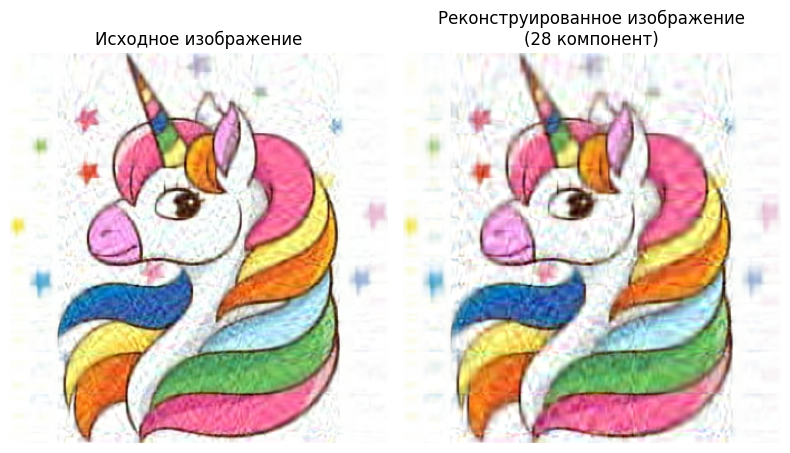

In [ ]:
plt.figure(figsize=(8, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(reconstructed_image)
plt.title('Реконструированное изображение'
          f'\n({pca_image.n_components_} компонент)')
plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
save_path = '/content/drive/MyDrive/Colab Notebooks/unicorn.avif'
reconstructed_image.save(save_path)


In [ ]:
pca_image_row_as_feature = PCA(n_components=0.95)
image_pca_row_as_feature = pca_image_row_as_feature.fit_transform(image_pca.T)
print(f'Исходная форма массива изображения: {image_pca.T.shape}')
print(f'Форма массива после PCA: {image_pca_row_as_feature.shape}')
print('Количество компонент, выбранных PCA: '
      f'{pca_image_row_as_feature.n_components_}')


Исходная форма массива изображения: (28, 350)
Форма массива после PCA: (28, 21)
Количество компонент, выбранных PCA: 21


In [ ]:
image_reconstructed_new = pca_image_row_as_feature.inverse_transform(
                                                       image_pca_row_as_feature)
image_reconstructed_new = pca_image.inverse_transform(image_reconstructed_new.T)
image_reconstructed_new = np.clip(image_reconstructed_new, 0, 1)
image_reconstructed_new = image_reconstructed_new.reshape(h, w, d)
image_reconstructed_new_uint8 = (image_reconstructed_new * 255).astype(np.uint8)
reconstructed_image_new = Image.fromarray(image_reconstructed_new_uint8)


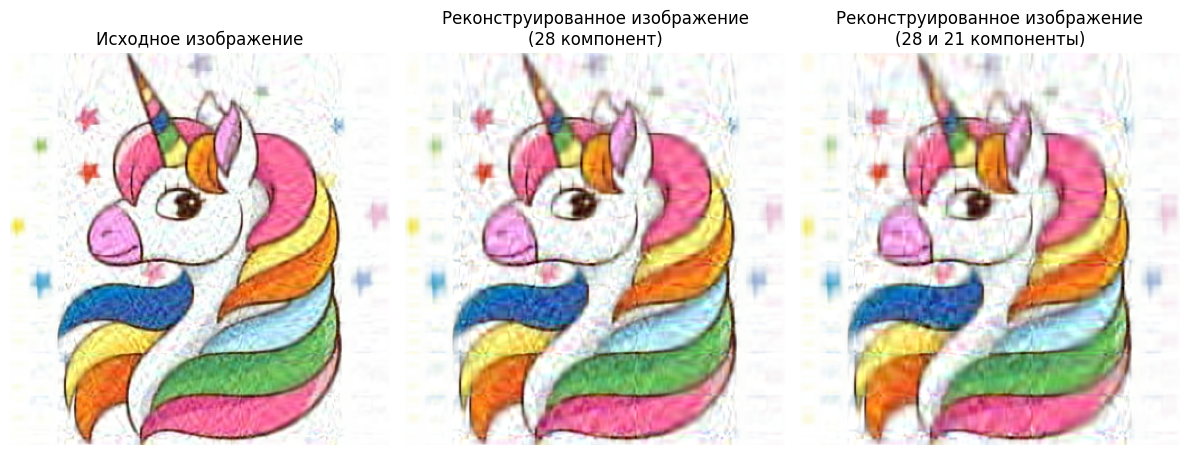

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(reconstructed_image)
plt.title('Реконструированное изображение'
          f'\n({pca_image.n_components_} компонент)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(reconstructed_image_new)
plt.title('Реконструированное изображение'
          f'\n({pca_image.n_components_} и '
          f'{pca_image_row_as_feature.n_components_} компоненты)')
plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
save_path = '/content/drive/MyDrive/Colab Notebooks/unicorn.avif'
reconstructed_image_new.save(save_path)


# Last example

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.datasets import fetch_openml


In [ ]:
mnist = fetch_openml(name='mnist_784', version=1, as_frame=False)
X = mnist.data
y = mnist.target


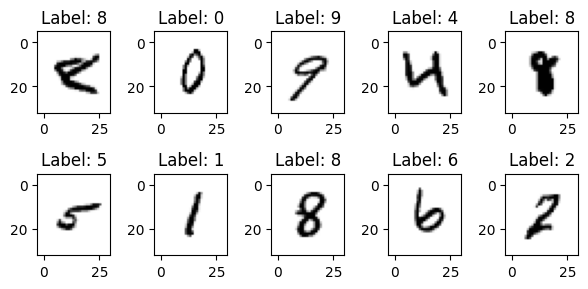

In [ ]:
random_indices = np.random.choice(len(X), 10, replace=False)
random_images = X[random_indices]
random_labels = y[random_indices]

plt.figure(figsize=(6, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(random_images[i].reshape(28, 28), cmap='gray_r')
    plt.title(f'Label: {random_labels[i]}')
    plt.axis('equal')

plt.tight_layout()
plt.show()


In [ ]:
X_processed = (X - np.mean(X, axis=0)) / np.max(np.std(X, axis=0))


In [ ]:
pca = PCA()
X_pca = pca.fit_transform(X_processed)


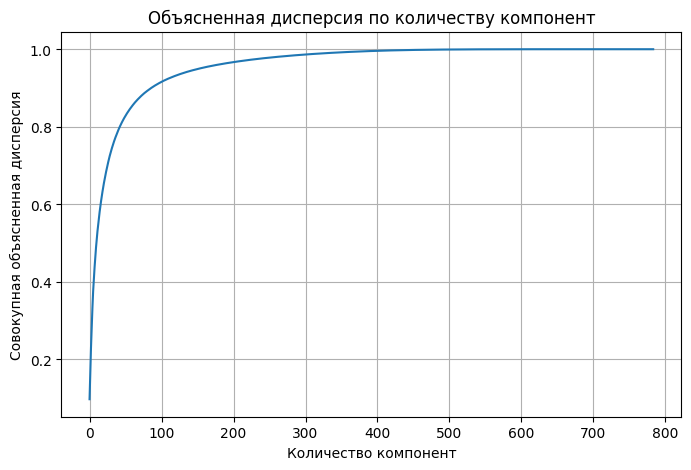

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Количество компонент')
plt.ylabel('Совокупная объясненная дисперсия')
plt.title('Объясненная дисперсия по количеству компонент')
plt.grid(True)
plt.show()


In [ ]:
pca_95 = PCA(n_components=0.95)
X_pca_95 = pca_95.fit_transform(X_processed)
print(f'Исходная форма массива изображения: {X_processed.shape}')
print(f'Форма массива после PCA: {X_pca_95.shape}')
print(f'Количество компонент, выбранных PCA: {pca_95.n_components_}')


Исходная форма массива изображения: (70000, 784)
Форма массива после PCA: (70000, 154)
Количество компонент, выбранных PCA: 154


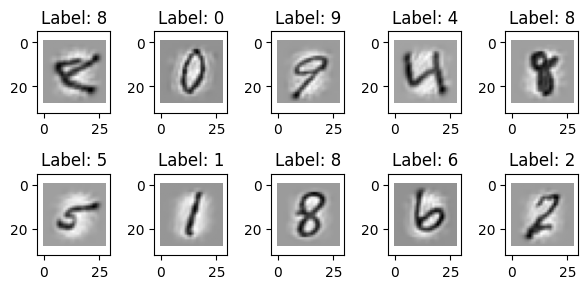

In [ ]:
X_reconstructed = pca_95.inverse_transform(X_pca_95)

plt.figure(figsize=(6, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_reconstructed[random_indices[i]].reshape(28, 28),
               cmap='gray_r')
    plt.title(f'Label: {y[random_indices[i]]}')
    plt.axis('equal')

plt.tight_layout()
plt.show()


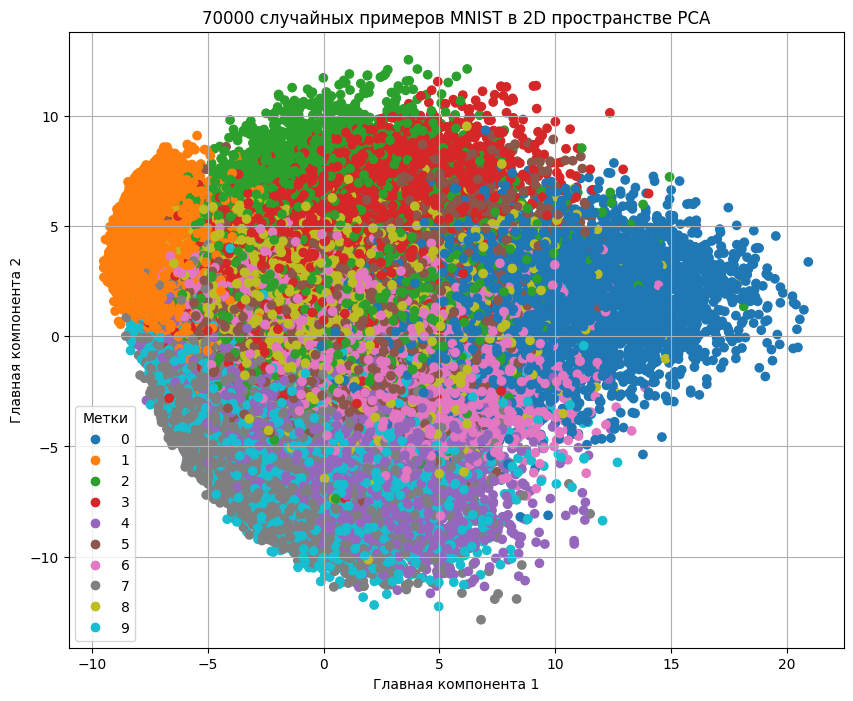

In [ ]:
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_processed)

np.random.seed(42)
n_samples = 70000
random_indices = np.random.choice(len(X_pca_2d), n_samples, replace=False)

X_2d_sample = X_pca_2d[random_indices]
y_sample = y[random_indices]
y_sample_int = y_sample.astype(int)

colors = plt.colormaps['tab10']

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_2d_sample[:, 0], X_2d_sample[:, 1],
                      c=y_sample_int, cmap=colors, alpha=1)

plt.legend(*scatter.legend_elements(), title='Метки')

plt.title(f'{n_samples} случайных примеров MNIST в 2D пространстве PCA')
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.grid(True)
plt.show()


In [ ]:
from sklearn.manifold import TSNE

n_samples_tsne = 5000
np.random.seed(42)
indices = np.random.choice(len(X_pca_95), n_samples_tsne, replace=False)

X_subset = X_pca_95[indices]
y_subset = y[indices]

print(f"Размер подвыборки для t-SNE: {X_subset.shape}")

Размер подвыборки для t-SNE: (5000, 154)


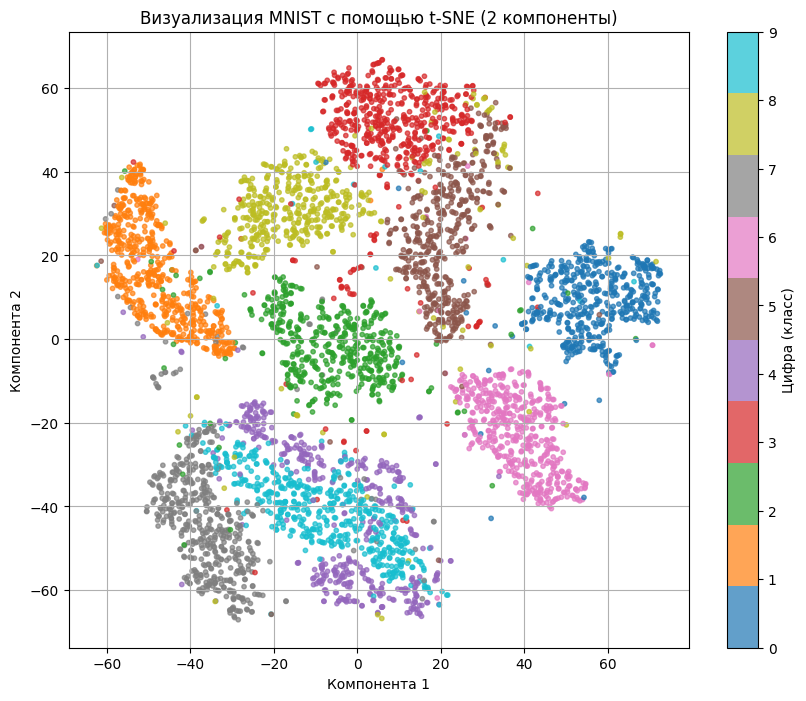

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

y_subset_int = y_subset.astype(int)
tsne_2d = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne_2d = tsne_2d.fit_transform(X_subset)

plt.figure(figsize=(10, 8))

scatter = plt.scatter(X_tsne_2d[:, 0], X_tsne_2d[:, 1],
                      c=y_subset_int, cmap='tab10', alpha=0.7, s=10)

plt.colorbar(scatter, ticks=range(10), label='Цифра (класс)')

plt.title('Визуализация MNIST с помощью t-SNE (2 компоненты)')
plt.xlabel('Компонента 1')
plt.ylabel('Компонента 2')
plt.grid(True)
plt.show()

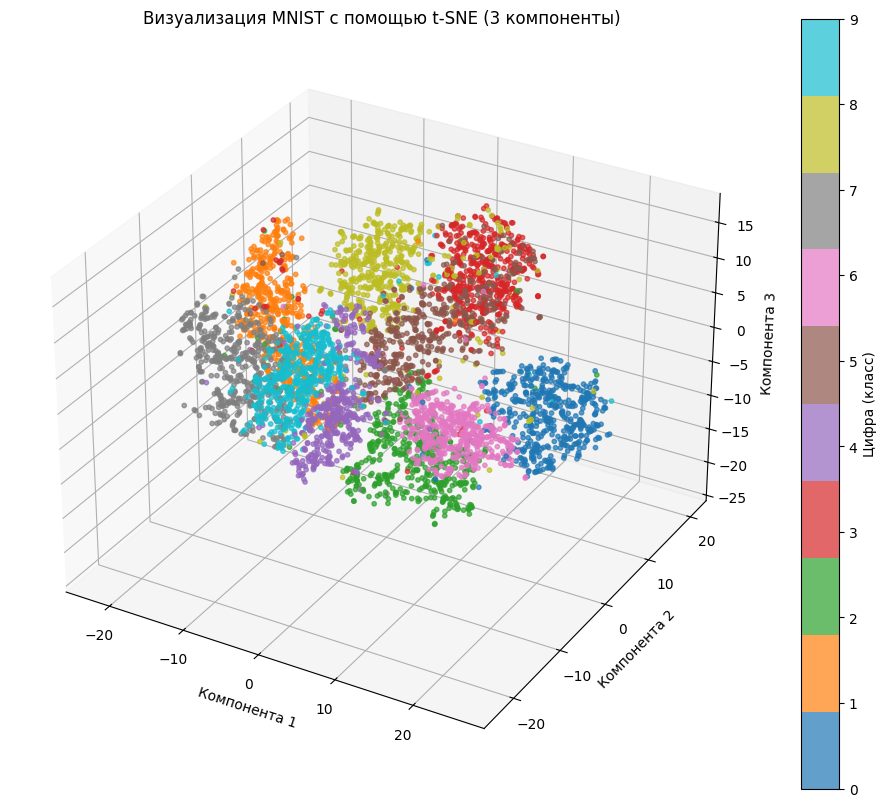

In [ ]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

tsne_3d = TSNE(n_components=3, random_state=42, perplexity=30)
X_tsne_3d = tsne_3d.fit_transform(X_subset)

fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

scatter_3d = ax.scatter(X_tsne_3d[:, 0], X_tsne_3d[:, 1], X_tsne_3d[:, 2],
                        c=y_subset.astype(int), cmap='tab10', alpha=0.7, s=10)

fig.colorbar(scatter_3d, label='Цифра (класс)')
ax.set_title('Визуализация MNIST с помощью t-SNE (3 компоненты)')
ax.set_xlabel('Компонента 1')
ax.set_ylabel('Компонента 2')
ax.set_zlabel('Компонента 3')
plt.show()